# Original semantic-analysis and review-pipeline walkthrough

Executed source inspection with actual prototype definitions. No reviews, embeddings, learned weights or new study estimates are generated.

In [1]:
from pathlib import Path
import ast,importlib.util,inspect,sys
import pandas as pd
from IPython.display import display,Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'METHOD_SOURCE_MAP.json').is_file())
def load_source(name,path):
    spec=importlib.util.spec_from_file_location(name,path)
    module=importlib.util.module_from_spec(spec);sys.modules[name]=module;spec.loader.exec_module(module)
    return module
def show_function(path,name):
    text=path.read_text();n=next(n for n in ast.parse(text).body if isinstance(n,(ast.FunctionDef,ast.ClassDef)) and n.name==name)
    print(ast.get_source_segment(text,n))

P=ROOT/'code/review_pipeline'
semantic=load_source('public_semantic_analysis',P/'semantic_analysis.py')

## 1. Actual 29 semantic definitions
These are the original banks, not synthetic review observations.

In [2]:
rows=[{'dimension':k,'positive_seeds':len(v['positive']),'negative_seeds':len(v['negative'])} for k,v in semantic.score_categories.items()]
display(pd.DataFrame(rows))
print('Dimensions:',len(rows),'· actual prototype sentences:',sum(r['positive_seeds']+r['negative_seeds'] for r in rows))
for name in ['Exploration_Behavior','Learning_Knowledge','Happiness','Satisfaction_SWLS']:
    print('\n'+name,semantic.score_categories[name])

,dimension,positive_seeds,negative_seeds
0,Happiness,3,3
1,Meaningfulness,3,3
2,Psychological_Richness,4,3
3,FG_Richness,3,2
4,Exploration_Behavior,5,5
5,Satisfaction_SWLS,5,5
6,Meaningfulness_MLQ,4,1
7,Purpose_MLQ,2,2
8,Appreciation,5,5
9,Mattering,2,2


Dimensions: 29 · actual prototype sentences: 275

Exploration_Behavior {'positive': ['This place made me want to try different things', 'I found myself exploring different options here', 'There was a lot to look around and discover here', 'I tried things here that I wouldn’t normally choose', 'This place made me curious to explore more'], 'negative': ['I just stuck with the usual option here', 'There was no reason to try anything different here', 'I didn’t feel the need to explore anything here', 'Everything here led me to make the same choice as usual', 'Nothing here encouraged me to look around or try something new']}

Learning_Knowledge {'positive': ['I learned something here', 'This was educational', 'This was informative', 'I gained new insights', 'This was enlightening'], 'negative': ['I learned nothing here', 'This was uninformative', 'This taught me nothing new']}

Happiness {'positive': ['This place made me happy', 'I enjoyed this experience', 'I felt comfortable here'], 'nega

## 2. Original semantic computation
The full module also contains the original review-chunk loop. Seed centroids precede the original half-precision/256-token review settings.

In [3]:
print(inspect.getsource(semantic.clean_text))
print(inspect.getsource(semantic.calculate_centroid_scores))
show_function(P/'semantic_analysis.py','run_semantic_generation')

def clean_text(text):
    if isinstance(text, str): return re.sub(r'[^A-Za-z0-9\s.,!\'\"]+', '', text)
    return text

def calculate_centroid_scores(embeddings):
    scores = {}
    for cat, centroids in centroid_scores.items():
        if "positive" in centroids and "negative" in centroids:
            direction = centroids["positive"] - centroids["negative"]
            scores[f'{cat}_Score'] = cosine_similarity(embeddings, [direction]).flatten()
        elif "positive" in centroids:
            scores[f'{cat}_Score'] = cosine_similarity(embeddings, [centroids["positive"]]).flatten()
        elif "negative" in centroids:
            scores[f'{cat}_Score'] = -cosine_similarity(embeddings, [centroids["negative"]]).flatten()
    return scores

def run_semantic_generation(model, review_path, temp_dir, *, year=2019,
                            batch_size=1024, chunk_size=100000, source_label="source"):
    """Original computation with explicit operational inputs; requires authorized revi

## 3. Frozen context policy and numerical classification
The external fitted artifact is withheld; this cell shows the original implementation, not new predictions.

In [4]:
show_function(P/'text_context_features_v1_1.py','extract_context')
show_function(P/'score_multitarget_v1_2_2.py','score_frame')

def extract_context(text: object)->dict[str,float]:
    raw="" if text is None or (isinstance(text,float) and math.isnan(text)) else str(text)
    tokens=[t.lower().replace("’","'") for t in WORD_RE.findall(raw)]
    content=[t for t in tokens if t not in STOPWORDS]
    ratio=sum(t in GENERIC_CONTENT for t in content)/len(content) if content else 0.0
    temporal=sum(t in TEMPORAL for t in tokens); event=sum(t in EVENT for t in tokens); cognitive=sum(t in COGNITIVE for t in tokens)
    n_digits=sum(ch.isdigit() for ch in raw)
    has_currency=bool(re.search(r"[$€£¥₹]|\b(?:usd|dollars?|bucks?|euros?|pounds?)\b",raw,re.I))
    has_duration=bool(re.search(r"\b\d+(?:\.\d+)?\s*(?:seconds?|secs?|minutes?|mins?|hours?|hrs?|days?|weeks?|months?|years?)\b",raw,re.I))
    has_date=bool(re.search(r"\b(?:\d{1,2}[:.]\d{2}\s*(?:am|pm)?|\d{1,2}\s*(?:am|pm)|(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\s+\d{1,2})\b",raw,re.I))
    generic=bool(len(tokens)<=15 and content and ratio>=.80 and

## 4. Annual aggregation and spatial coverage
All annual source rows enter duplicate accounting before eligibility exclusions. The place cohort uses at least 50 eligible clusters.

In [5]:
show_function(P/'aggregate_annual_four_targets.py','cluster_sql')
show_function(P/'spatial_coverage.py','build_reach')

def cluster_sql():
    w='within_place_duplicate_weight'
    e='CAST(common_eligible_substantive AS INTEGER)'
    expressions=["gmap_id","normalized_text_hash","count(*) AS raw_rows",
                 f"sum({e}) AS eligible_rows",f"sum({w}) AS all_mass",f"sum({w}*{e}) AS eligible_mass",
                 "min(normalized_duplicate_count_within_place) AS declared_min",
                 "max(normalized_duplicate_count_within_place) AS declared_max",
                 f"min({e}) AS eligibility_min",f"max({e}) AS eligibility_max"]
    for tid in RAW:
        expressions += [f"sum({w}*{q(RAW[tid])}) AS {q('L0_'+tid+'_sum')}",
                        f"sum({w}*{e}*{q(RAW[tid])}) AS {q('L1_'+tid+'_sum')}",
                        f"sum({w}*{e}*{q(TARGET[tid]+'__evidence_probability')}) AS {q('L2_'+tid+'_sum')}",
                        f"sum({w}*{e}*CAST({q(TARGET[tid]+'__fixed_p05_call')} AS DOUBLE)) AS {q('L3_'+tid+'_sum')}"]
    return "SELECT "+','.join(expressions)+" FROM r GROUP BY gmap_id

## 5. Existing actual result figure
This figure is unchanged from the published selected sample. No city-level analysis rows are loaded here.

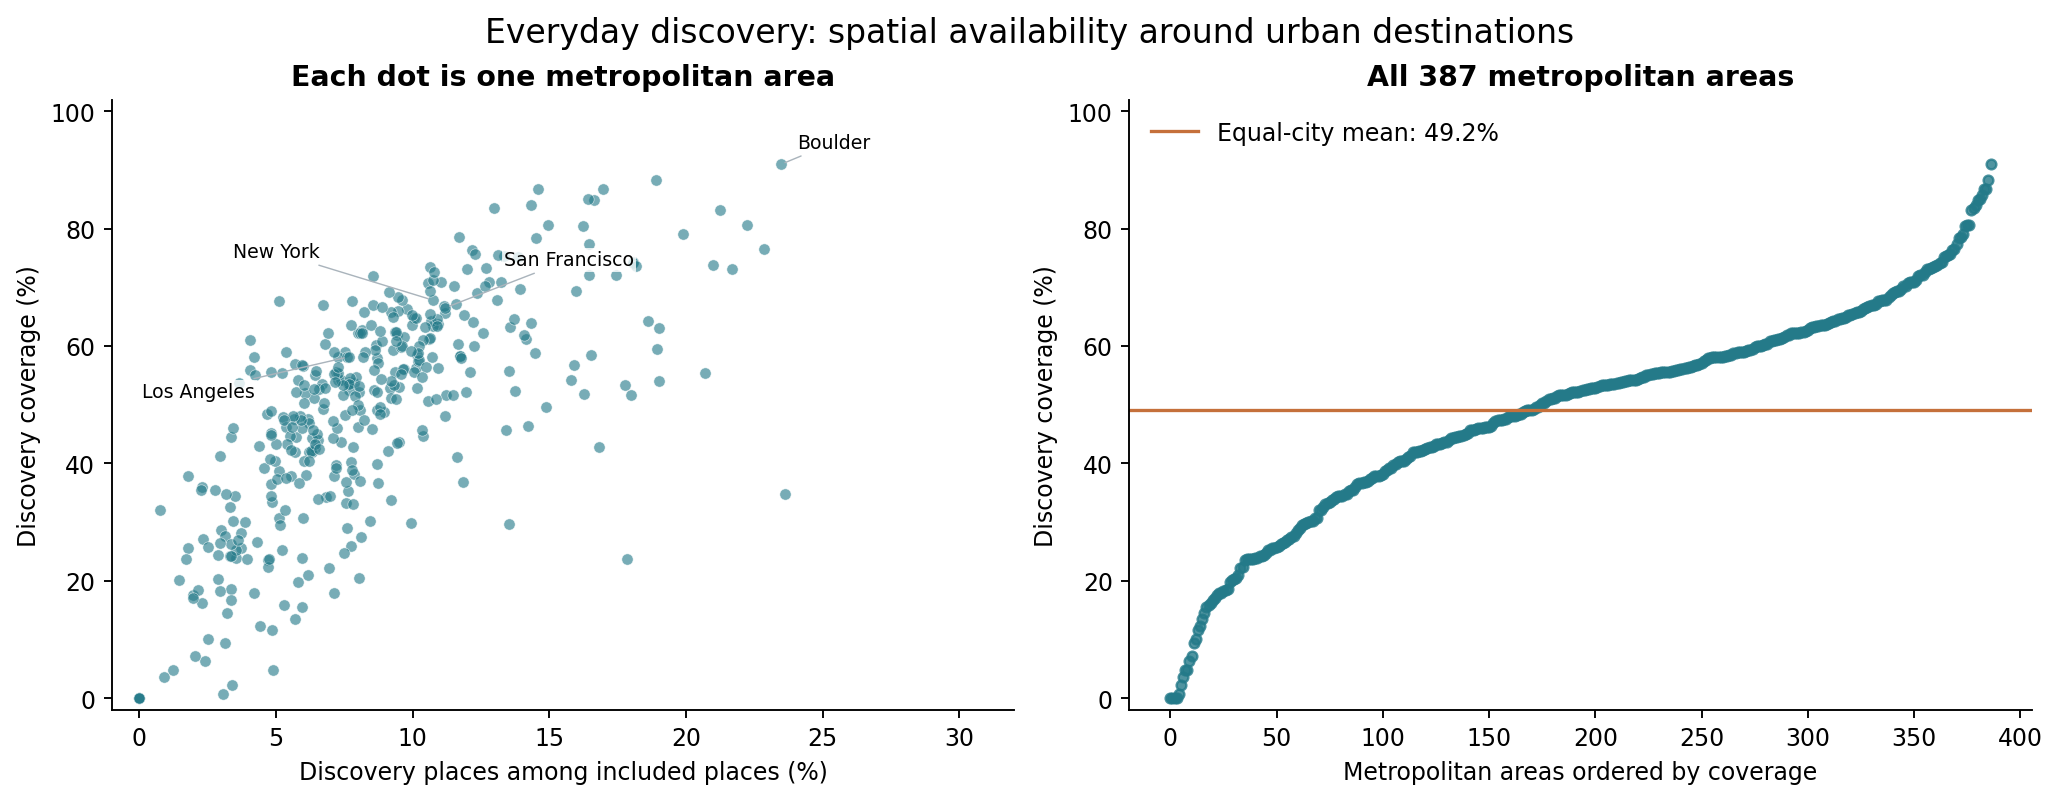

In [6]:
display(Image(filename=str(ROOT/'figures/01_actual_city_patterns.png')))

See `METHODS_AND_INPUTS.md` for the original alignment/identification limits, exact stage inputs and source provenance. The separate selected-results notebook displays the saved estimate tables.